In [1]:
import gc
import numpy as np
import polars as pl
from scipy.stats import skew, kurtosis
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.stattools import kpss
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

### <b>Global Variables.</b>

In [2]:
# Paths for BTCUSDT.
PATH_BINANCE_PERP_BTCUSDT_LOB       = r'data\binance_booktickers\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_LIQUID    = r'data\binance_liquidations\perp_btcusdt.parquet'
PATH_BYBIT_PERP_BTCUSDT_LIQUID      = r'data\bybit_liquidations\btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_TRADES    = r'data\binance_trades\perp_btcusdt.parquet'

# Paths for ETHUSDT.
PATH_BINANCE_PERP_ETHUSDT_LOB       = r'data\binance_booktickers\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_LIQUID    = r'data\binance_liquidations\perp_ethusdt.parquet'
PATH_BYBIT_PERP_ETHUSDT_LIQUID      = r'data\bybit_liquidations\ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_TRADES    = r'data\binance_trades\perp_ethusdt.parquet'

# All .parquet files.
PARQUET_FILES = {
    "binance_perp_btcusdt_lob": PATH_BINANCE_PERP_BTCUSDT_LOB,
    "binance_perp_btcusdt_liquid": PATH_BINANCE_PERP_BTCUSDT_LIQUID,
    "bybit_perp_btcusdt_liquid": PATH_BYBIT_PERP_BTCUSDT_LIQUID,
    "binance_perp_btcusdt_trades": PATH_BINANCE_PERP_BTCUSDT_TRADES,

    "binance_perp_ethusdt_lob": PATH_BINANCE_PERP_ETHUSDT_LOB,
    "binance_perp_ethusdt_liquid": PATH_BINANCE_PERP_ETHUSDT_LIQUID,
    "bybit_perp_ethusdt_liquid": PATH_BYBIT_PERP_ETHUSDT_LIQUID,
    "binance_perp_ethusdt_trades": PATH_BINANCE_PERP_ETHUSDT_TRADES,
}

In [3]:
features_full = [
    # LOB
    "mid_close", "mid_std", "avg_spread", "return_1m",
    # trades
    "trade_volume", "trade_count", "buy_volume", "sell_volume", "trade_imbalance",
    # liquidations binance
    "liq_binance_volume", "liq_binance_count", "liq_binance_buy", "liq_binance_sell",
    # liquidations bybit
    "liq_bybit_volume", "liq_bybit_count", "liq_bybit_buy", "liq_bybit_sell",
    # total liquidations
    "liq_total_volume", "liq_total_count",
]

features_shrink = [
    "return_1m", "mid_std", "avg_spread",
    "trade_volume", "trade_count", "trade_imbalance",
    "liq_total_volume", "liq_total_count",
    "liq_binance_volume", "liq_bybit_volume",
]

## **Features Analysis.**

Building minute level features from all data sources and analyzing their statistical properties for signal construction.

1. **Feature Construction.** Aggregate trades, LOB, and liquidations into 1-minute bars and build features.
2. **Stationarity.** ADF + KPSS tests - which features are stationary and can be used directly.
3. **Autocorrelation.** ACF at 1–60 min lags - which features have memory and predictive power.
4. **Outlier Structure.** Quantiles, kurtosis, tail behavior - do we need robust normalization.
5. **Non-linearities.** Binned means - are feature-target relationships linear or not.
6. **Regime Structure.** Based on Liquidations.
7. **Correlation Matrix.** Pearson + Spearman - which features are redundant, which are unique.

### <b>1.1 Feature Construction.</b>

In [4]:
def build_minute_features(
    lf_trades: pl.LazyFrame,
    lf_lob: pl.LazyFrame,
    lf_liq_binance: pl.LazyFrame,
    lf_liq_bybit: pl.LazyFrame,
) -> pl.DataFrame:
    """
    Aggregates all data sources into 1-minute bars with features.
    """

    # trades: volume, count, imbalance.
    df_trades = (
        lf_trades
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            (pl.col("price") * pl.col("amount")).alias("dollar_amount"),
            pl.col("side"),
        )
        .group_by("minute")
        .agg(
            pl.col("dollar_amount").sum().alias("trade_volume"),
            pl.len().alias("trade_count"),
            pl.col("dollar_amount").filter(pl.col("side") == "buy").sum().alias("buy_volume"),
            pl.col("dollar_amount").filter(pl.col("side") == "sell").sum().alias("sell_volume"),
        )
        .with_columns(
            ((pl.col("buy_volume") - pl.col("sell_volume"))
             / (pl.col("buy_volume") + pl.col("sell_volume")))
            .alias("trade_imbalance")
        )
        .sort("minute")
        .collect(engine="streaming")
    )

    gc.collect()

    # LOB: mid close, spread, volatility.
    df_lob = (
        lf_lob
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            ((pl.col("bid_price") + pl.col("ask_price")) / 2).alias("mid"),
            (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
        )
        .group_by("minute")
        .agg(
            pl.col("mid").last().alias("mid_close"),
            pl.col("mid").std().alias("mid_std"),
            pl.col("spread").mean().alias("avg_spread"),
        )
        .sort("minute")
        .collect(engine="streaming")
    )

    gc.collect()

    # returns.
    df_lob = df_lob.with_columns(
        (pl.col("mid_close").pct_change() * 100).alias("return_1m"),
    )

    # liquidations binance.
    df_liq_b = (
        lf_liq_binance
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            (pl.col("price") * pl.col("amount")).alias("dollar_amount"),
            pl.col("side"),
        )
        .group_by("minute")
        .agg(
            pl.col("dollar_amount").sum().alias("liq_binance_volume"),
            pl.len().alias("liq_binance_count"),
            pl.col("dollar_amount").filter(pl.col("side") == "buy").sum().alias("liq_binance_buy"),
            pl.col("dollar_amount").filter(pl.col("side") == "sell").sum().alias("liq_binance_sell"),
        )
        .sort("minute")
        .collect(engine="streaming")
    )

    gc.collect()

    # liquidations bybit (+200ms delay, from `description.md`).
    df_liq_by = (
        lf_liq_bybit
        .with_columns(
            (pl.col("timestamp") + 200_000).alias("timestamp")
        )
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            (pl.col("price") * pl.col("amount")).alias("dollar_amount"),
            pl.col("side"),
        )
        .group_by("minute")
        .agg(
            pl.col("dollar_amount").sum().alias("liq_bybit_volume"),
            pl.len().alias("liq_bybit_count"),
            pl.col("dollar_amount").filter(pl.col("side") == "buy").sum().alias("liq_bybit_buy"),
            pl.col("dollar_amount").filter(pl.col("side") == "sell").sum().alias("liq_bybit_sell"),
        )
        .sort("minute")
        .collect(engine="streaming")
    )

    gc.collect()

    # join all.
    df = (
        df_lob
        .join(df_trades, on="minute", how="left")
        .join(df_liq_b, on="minute", how="left")
        .join(df_liq_by, on="minute", how="left")
        .with_columns(
            pl.col("liq_binance_volume").fill_null(0),
            pl.col("liq_binance_count").fill_null(0),
            pl.col("liq_bybit_volume").fill_null(0),
            pl.col("liq_bybit_count").fill_null(0),
            pl.col("liq_binance_buy").fill_null(0),
            pl.col("liq_binance_sell").fill_null(0),
            pl.col("liq_bybit_buy").fill_null(0),
            pl.col("liq_bybit_sell").fill_null(0),
        )
        .with_columns(
            (pl.col("liq_binance_volume") + pl.col("liq_bybit_volume")).alias("liq_total_volume"),
            (pl.col("liq_binance_count") + pl.col("liq_bybit_count")).alias("liq_total_count"),
        )
    )

    # datetime.
    df = df.with_columns(
        (pl.col("minute") * 60 * 1000).cast(pl.Datetime("ms")).alias("datetime")
    )

    return df

In [5]:
# parse the data.
lf_btc_trades       = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_TRADES)
lf_btc_lob          = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LOB)
lf_btc_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LIQUID)
lf_btc_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_BTCUSDT_LIQUID)

lf_eth_trades       = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_TRADES)
lf_eth_lob          = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_LOB)
lf_eth_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_LIQUID)
lf_eth_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_ETHUSDT_LIQUID)

# build features.
df_btc = build_minute_features(lf_btc_trades, lf_btc_lob, lf_btc_liq_binance, lf_btc_liq_bybit)
df_eth = build_minute_features(lf_eth_trades, lf_eth_lob, lf_eth_liq_binance, lf_eth_liq_bybit)

### <b>1.2 Stationarity.</b>

In [6]:
import warnings

def stationarity_tests(
    df: pl.DataFrame,
    columns: list[str]
) -> pl.DataFrame:
    """
    Runs ADF and KPSS tests on each column.
    """
    results = []
    
    for col in columns:
        series = df[col].drop_nulls().to_numpy()
        
        # ADF test. H0: non-stationary.
        adf_stat, adf_pval, *_ = adfuller(series, maxlag=60)
        
        # KPSS test. H0: stationary.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kpss_stat, kpss_pval, *_ = kpss(series, regression="c", nlags="auto")
        
        # verdict, based on statsmodels documentation.
        # https://www.statsmodels.org/devel/examples/notebooks/generated/stationarity_detrending_adf_kpss.html
        if adf_pval < 0.05 and kpss_pval > 0.05:
            verdict = "strict stationary"
        elif adf_pval > 0.05 and kpss_pval > 0.05:
            verdict = "trend stationary"
        elif adf_pval > 0.05 and kpss_pval < 0.05:
            verdict = "non-stationary"
        elif adf_pval < 0.05 and kpss_pval < 0.05:
            verdict = "difference stationary"
        
        results.append({
            "feature": col,
            "adf_stat": round(adf_stat, 4),
            "adf_pval": round(adf_pval, 4),
            "kpss_stat": round(kpss_stat, 4),
            "kpss_pval": round(kpss_pval, 4),
            "verdict": verdict,
        })
    
    return pl.DataFrame(results)

In [7]:
# calc stats.
df_btc_stationarity = stationarity_tests(df_btc, features_full)
df_eth_stationarity = stationarity_tests(df_eth, features_full)

# show BTC results.
display(df_btc_stationarity)
print(df_btc_stationarity["verdict"].to_numpy())

# show ETH results.
display(df_eth_stationarity)
print(df_eth_stationarity["verdict"].to_numpy())

feature,adf_stat,adf_pval,kpss_stat,kpss_pval,verdict
str,f64,f64,f64,f64,str
"""mid_close""",-0.3308,0.921,43.2674,0.01,"""non-stationary"""
"""mid_std""",-17.0449,0.0,2.6082,0.01,"""difference stationary"""
"""avg_spread""",-38.086,0.0,1.485,0.01,"""difference stationary"""
"""return_1m""",-47.4171,0.0,0.1412,0.1,"""strict stationary"""
"""trade_volume""",-25.0384,0.0,1.1166,0.01,"""difference stationary"""
…,…,…,…,…,…
"""liq_bybit_count""",-38.1209,0.0,1.8323,0.01,"""difference stationary"""
"""liq_bybit_buy""",-71.9879,0.0,0.2028,0.1,"""strict stationary"""
"""liq_bybit_sell""",-48.2296,0.0,1.0293,0.01,"""difference stationary"""


['non-stationary' 'difference stationary' 'difference stationary'
 'strict stationary' 'difference stationary' 'difference stationary'
 'difference stationary' 'difference stationary' 'strict stationary'
 'difference stationary' 'difference stationary' 'difference stationary'
 'difference stationary' 'difference stationary' 'difference stationary'
 'strict stationary' 'difference stationary' 'difference stationary'
 'difference stationary']


feature,adf_stat,adf_pval,kpss_stat,kpss_pval,verdict
str,f64,f64,f64,f64,str
"""mid_close""",-0.2528,0.9319,44.4306,0.01,"""non-stationary"""
"""mid_std""",-18.8156,0.0,1.5851,0.01,"""difference stationary"""
"""avg_spread""",-60.5551,0.0,0.7596,0.01,"""difference stationary"""
"""return_1m""",-47.0053,0.0,0.1805,0.1,"""strict stationary"""
"""trade_volume""",-27.9728,0.0,0.7618,0.01,"""difference stationary"""
…,…,…,…,…,…
"""liq_bybit_count""",-49.172,0.0,1.1514,0.01,"""difference stationary"""
"""liq_bybit_buy""",-41.406,0.0,0.1276,0.1,"""strict stationary"""
"""liq_bybit_sell""",-60.1018,0.0,0.6227,0.0206,"""difference stationary"""


['non-stationary' 'difference stationary' 'difference stationary'
 'strict stationary' 'difference stationary' 'difference stationary'
 'difference stationary' 'difference stationary' 'difference stationary'
 'difference stationary' 'difference stationary' 'strict stationary'
 'difference stationary' 'difference stationary' 'difference stationary'
 'strict stationary' 'difference stationary' 'difference stationary'
 'difference stationary']


### **Stationarity Results.**
- `mid_close` - non-stationary. Use only via returns (or Fractional Differntion by Lopez De Prado).
- `return_1m`, `liq_bybit_buy` - fully stationary. Can be used directly.
- All other features - trend-stationary. Require Online EMA z-score normalization before modeling.

### <b>1.3 Autocorrelation.</b>

In [23]:
def plot_acf_features(
    df: pl.DataFrame, 
    columns: list[str], 
    name: str,
    nlags: int = 60
):
    """
    Plots ACF for each feature up to nlags minutes.
    """
    n_cols = 3
    n_rows = (len(columns) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(columns):
        series = df[col].drop_nulls().to_numpy()
        acf_vals = acf(series, nlags=nlags, fft=True)
        
        axes[i].bar(range(nlags + 1), acf_vals, width=0.8, alpha=0.7)
        axes[i].axhline(y=1.96 / np.sqrt(len(series)), color="r", linestyle="--", alpha=0.5)
        axes[i].axhline(y=-1.96 / np.sqrt(len(series)), color="r", linestyle="--", alpha=0.5)
        axes[i].set_title(col)
        axes[i].set_xlabel("Lag.")
        axes[i].set_ylabel("ACF.")
    
    # hide unused axes.
    for i in range(len(columns), len(axes)):
        axes[i].set_visible(False)
    
    fig.suptitle(f"{name} - Autocorrelation (60 min lags)", fontsize=14)
    plt.tight_layout()
    plt.show()

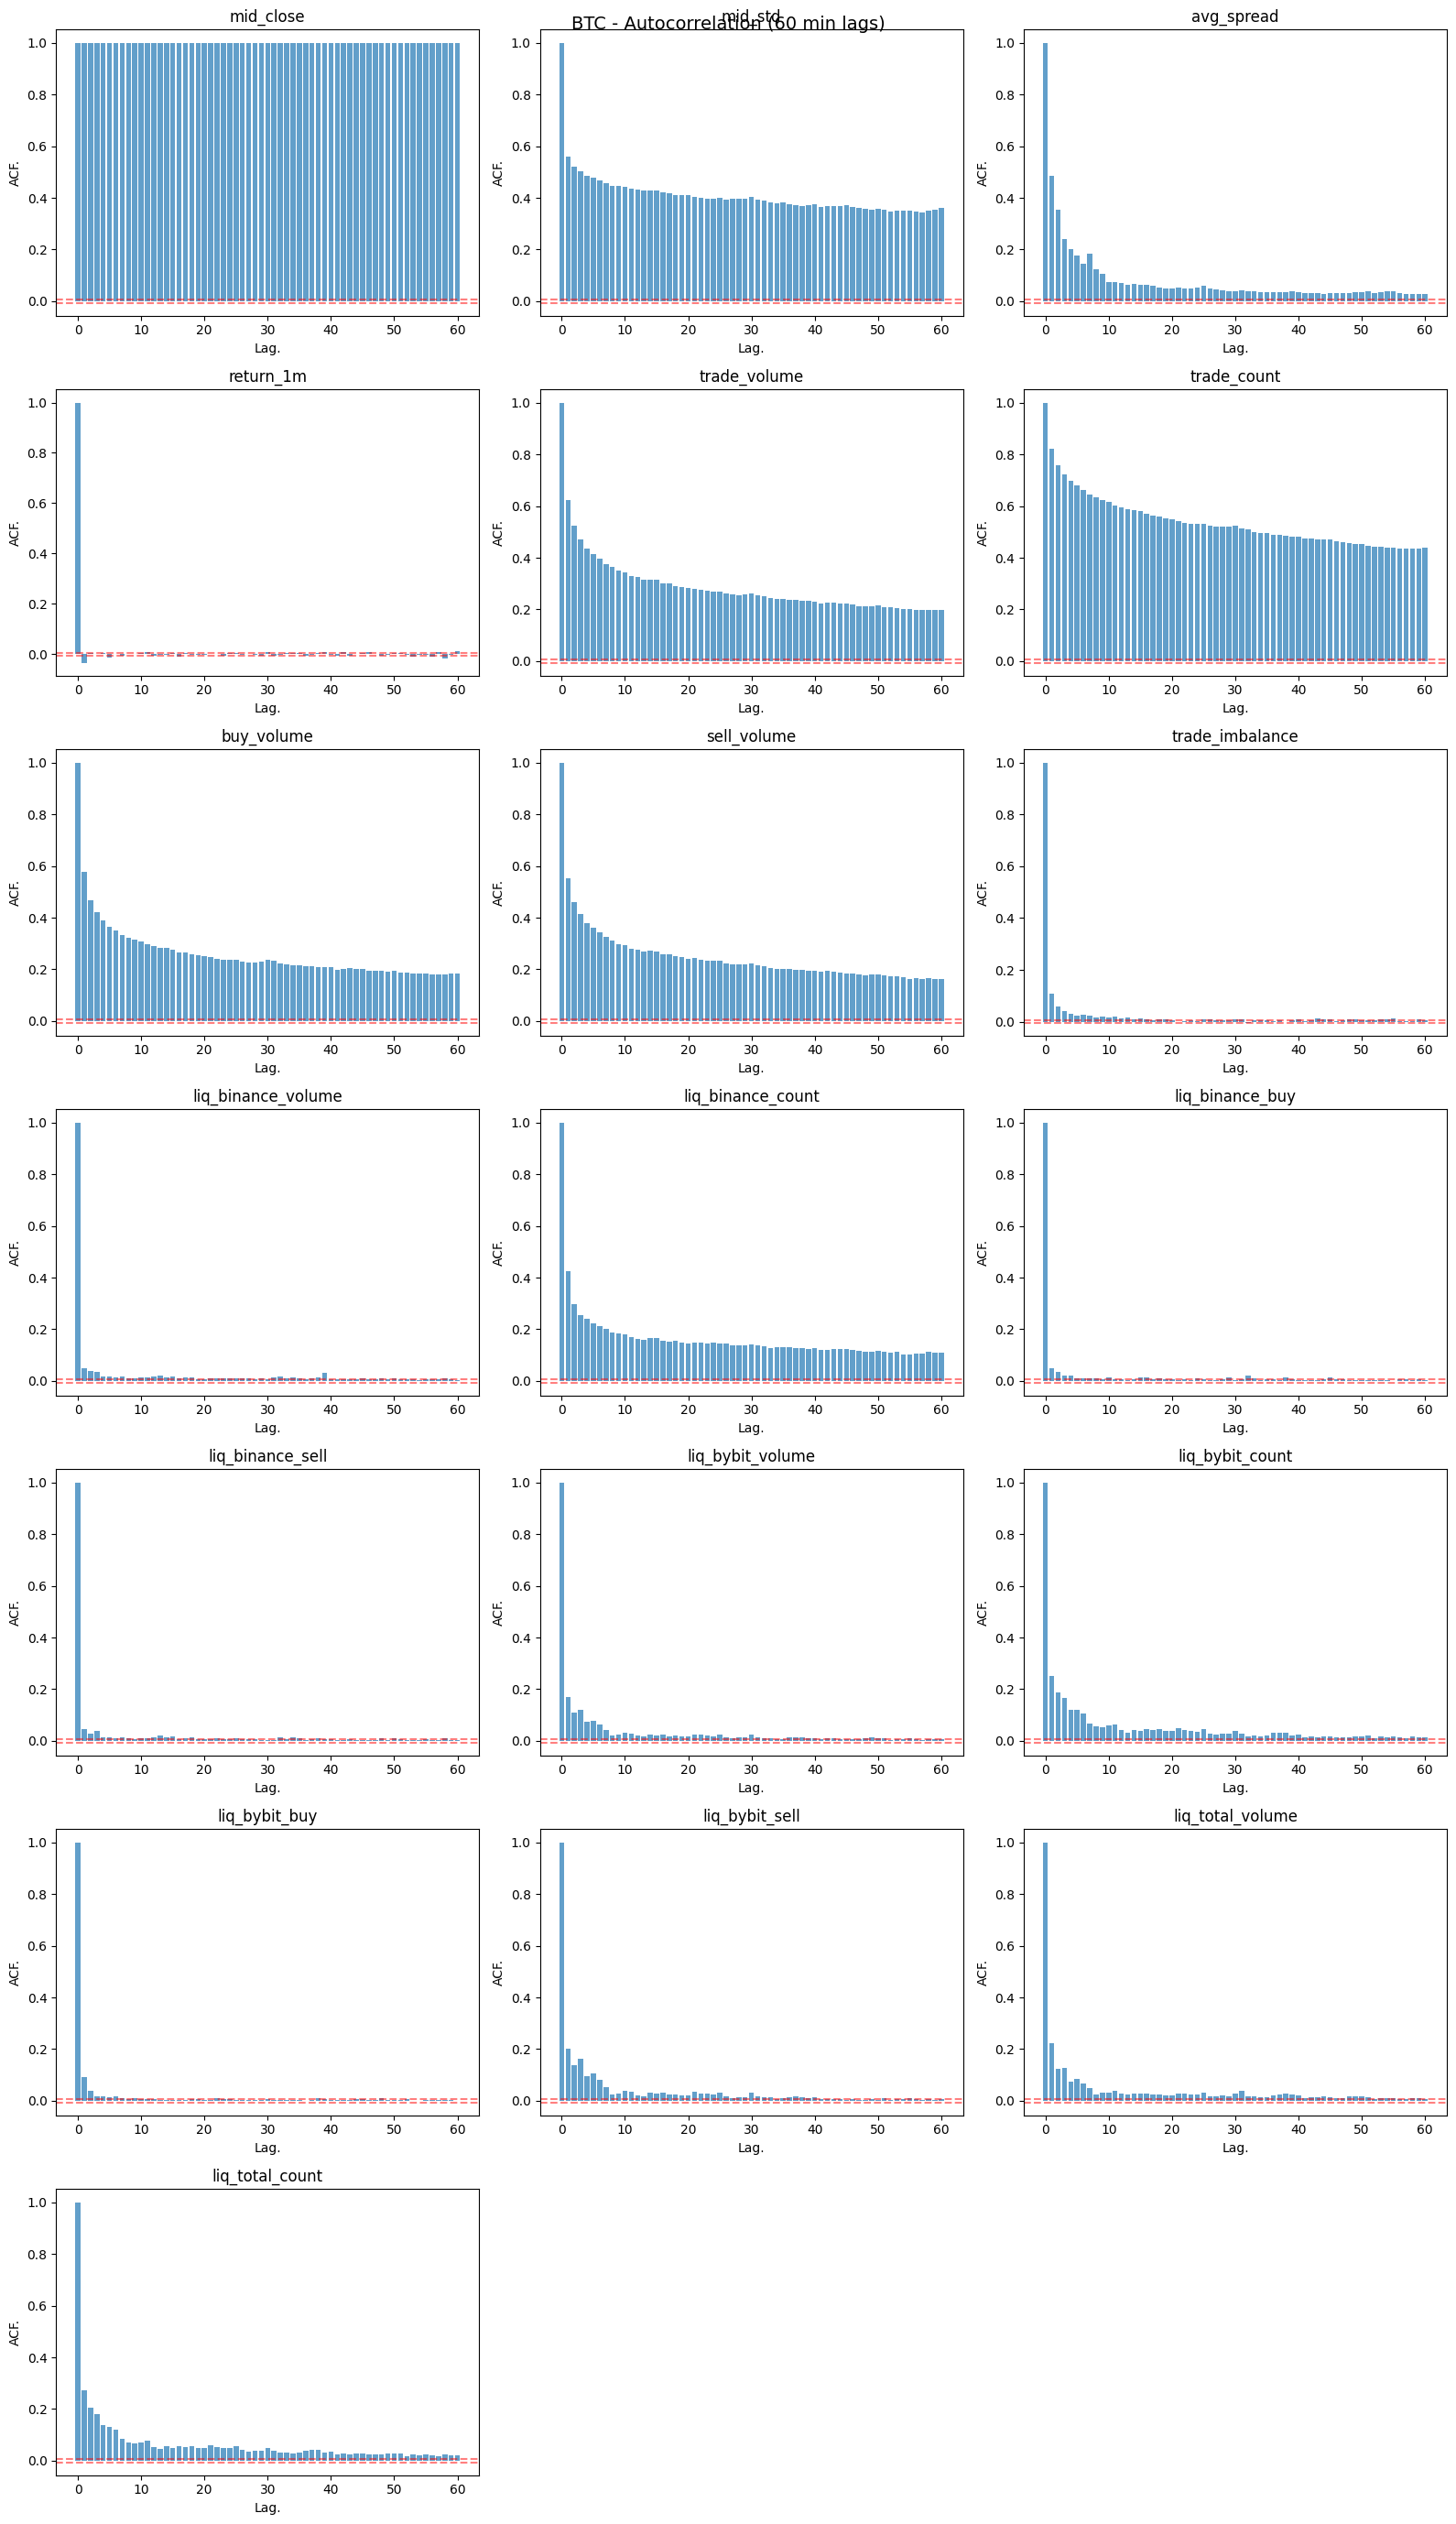

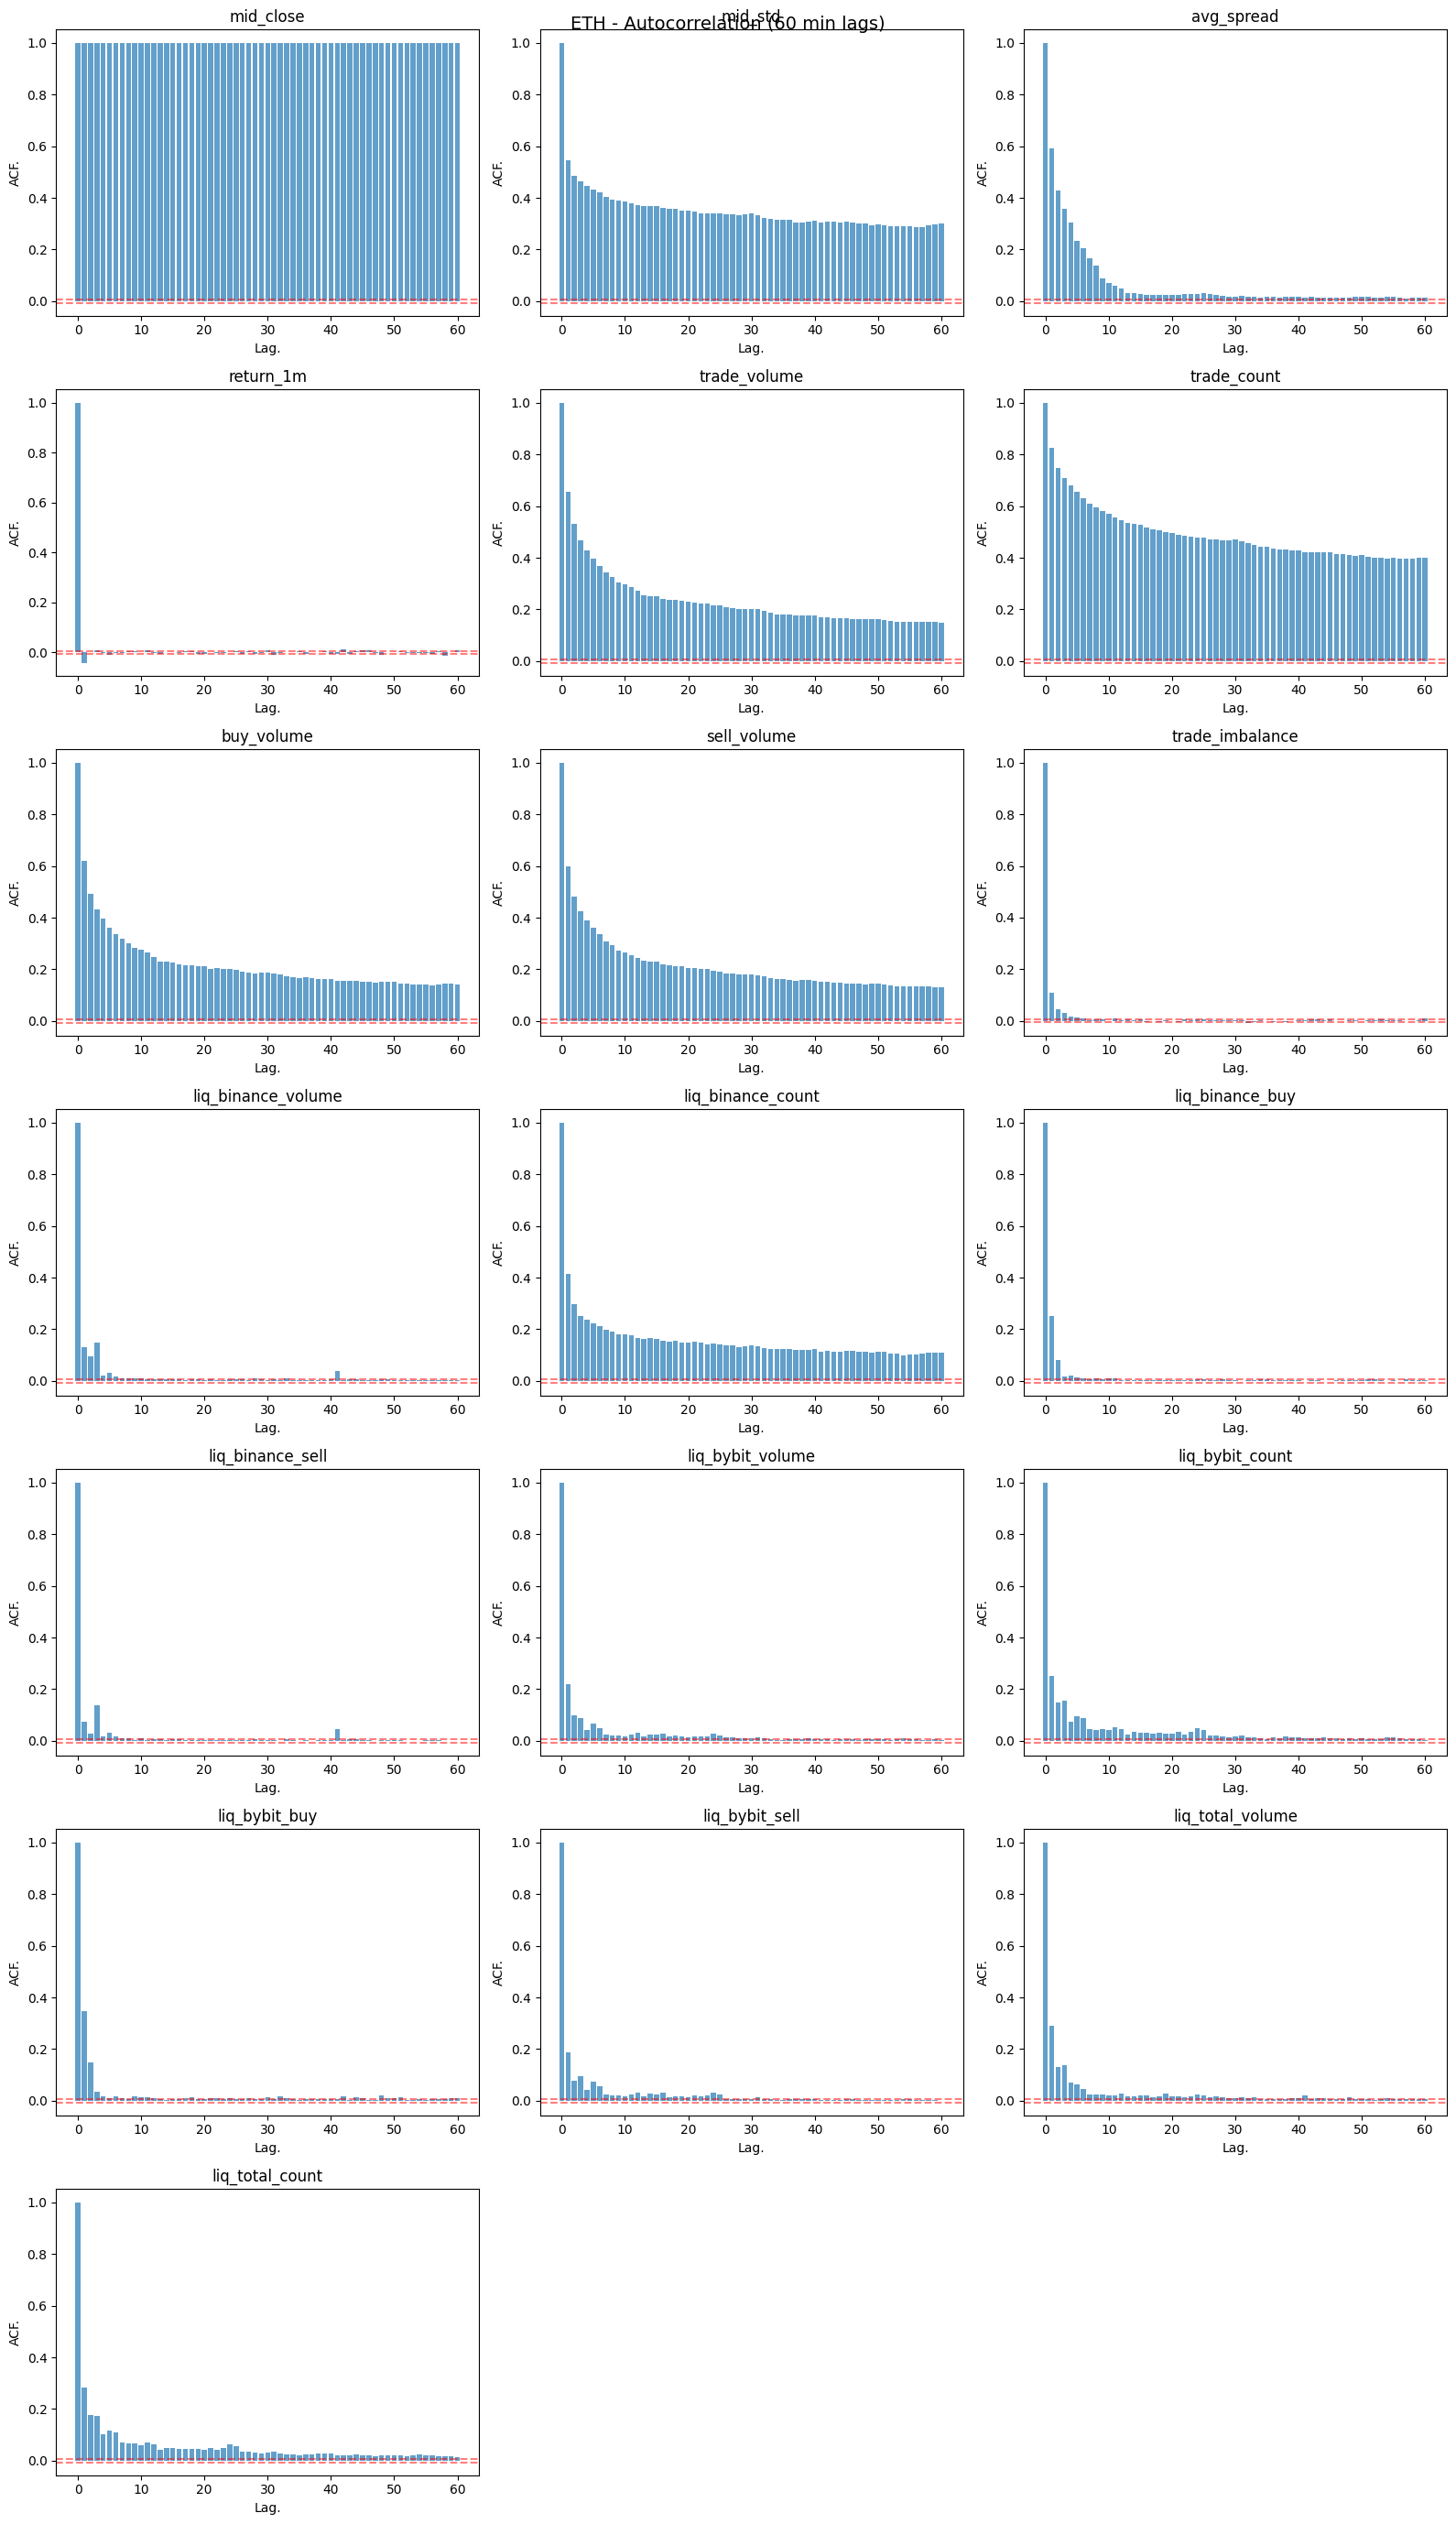

In [ ]:
plot_acf_features(df_btc, features_full, "BTC")
plot_acf_features(df_eth, features_full, "ETH")

### **Autocorrelation Results.**
- `return_1m` - near-zero ACF. Market efficient, past returns don't predict future.
- `mid_std`, `trade_volume`, `trade_count` - slow decay (0.4–0.6 at lag 60). Volatility and volume cluster over hours.
- `liq_total_volume/count` - significant at 2–5 min lags, then decays. Liquidations cluster on short horizons.
- Implication: use 1–5 min windows for liquidation features, 30–60 min for volume/volatility.

### <b>1.4 Outlier Structure.</b>

In [ ]:
def plot_outlier_structure(
    df: pl.DataFrame,
    columns: list[str],
    name: str
):
    """
    Analyzes tail behavior: quantiles, share of extreme values, and boxplots for each feature.
    """
    
    # quantile table
    results = []
    for col in columns:
        series = df[col].drop_nulls()
        results.append({
        "feature": col,
        "p1": round(float(series.quantile(0.01)), 6),
        "p5": round(float(series.quantile(0.05)), 6),
        "p50": round(float(series.quantile(0.50)), 6),
        "p95": round(float(series.quantile(0.95)), 6),
        "p99": round(float(series.quantile(0.99)), 6),
        "mean": round(float(series.mean()), 6),
        "std": round(float(series.std()), 6),
        "skew": 0.0,       
        "kurtosis": 0.0,   
        "kurtosis_ratio": round(
            float(series.quantile(0.99) - series.quantile(0.01))
            / float(series.quantile(0.75) - series.quantile(0.25) + 1e-12), 2
        ),
    })
    
    for i, col in enumerate(columns):
        arr = df[col].drop_nulls().to_numpy().astype(float)
        results[i]["skew"] = round(float(skew(arr)), 4)
        results[i]["kurtosis"] = round(float(kurtosis(arr)), 4)
    
    df_quantiles = pl.DataFrame(results)
    #display(df_quantiles)
    
    # boxplots.
    n_cols = 3
    n_rows = (len(columns) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(columns):
        arr = df[col].drop_nulls().to_numpy().astype(float)
        axes[i].hist(arr, bins=100, edgecolor="black", alpha=0.7)
        axes[i].set_yscale("log")
        axes[i].axvline(x=np.percentile(arr, 1), color="r", linestyle="--", alpha=0.7, label="p1/p99")
        axes[i].axvline(x=np.percentile(arr, 99), color="r", linestyle="--", alpha=0.7)
        axes[i].set_title(col)
        axes[i].legend()
    
    for i in range(len(columns), len(axes)):
        axes[i].set_visible(False)
    
    fig.suptitle(f"{name} - Outlier Structure", fontsize=14)
    plt.tight_layout()
    plt.show()

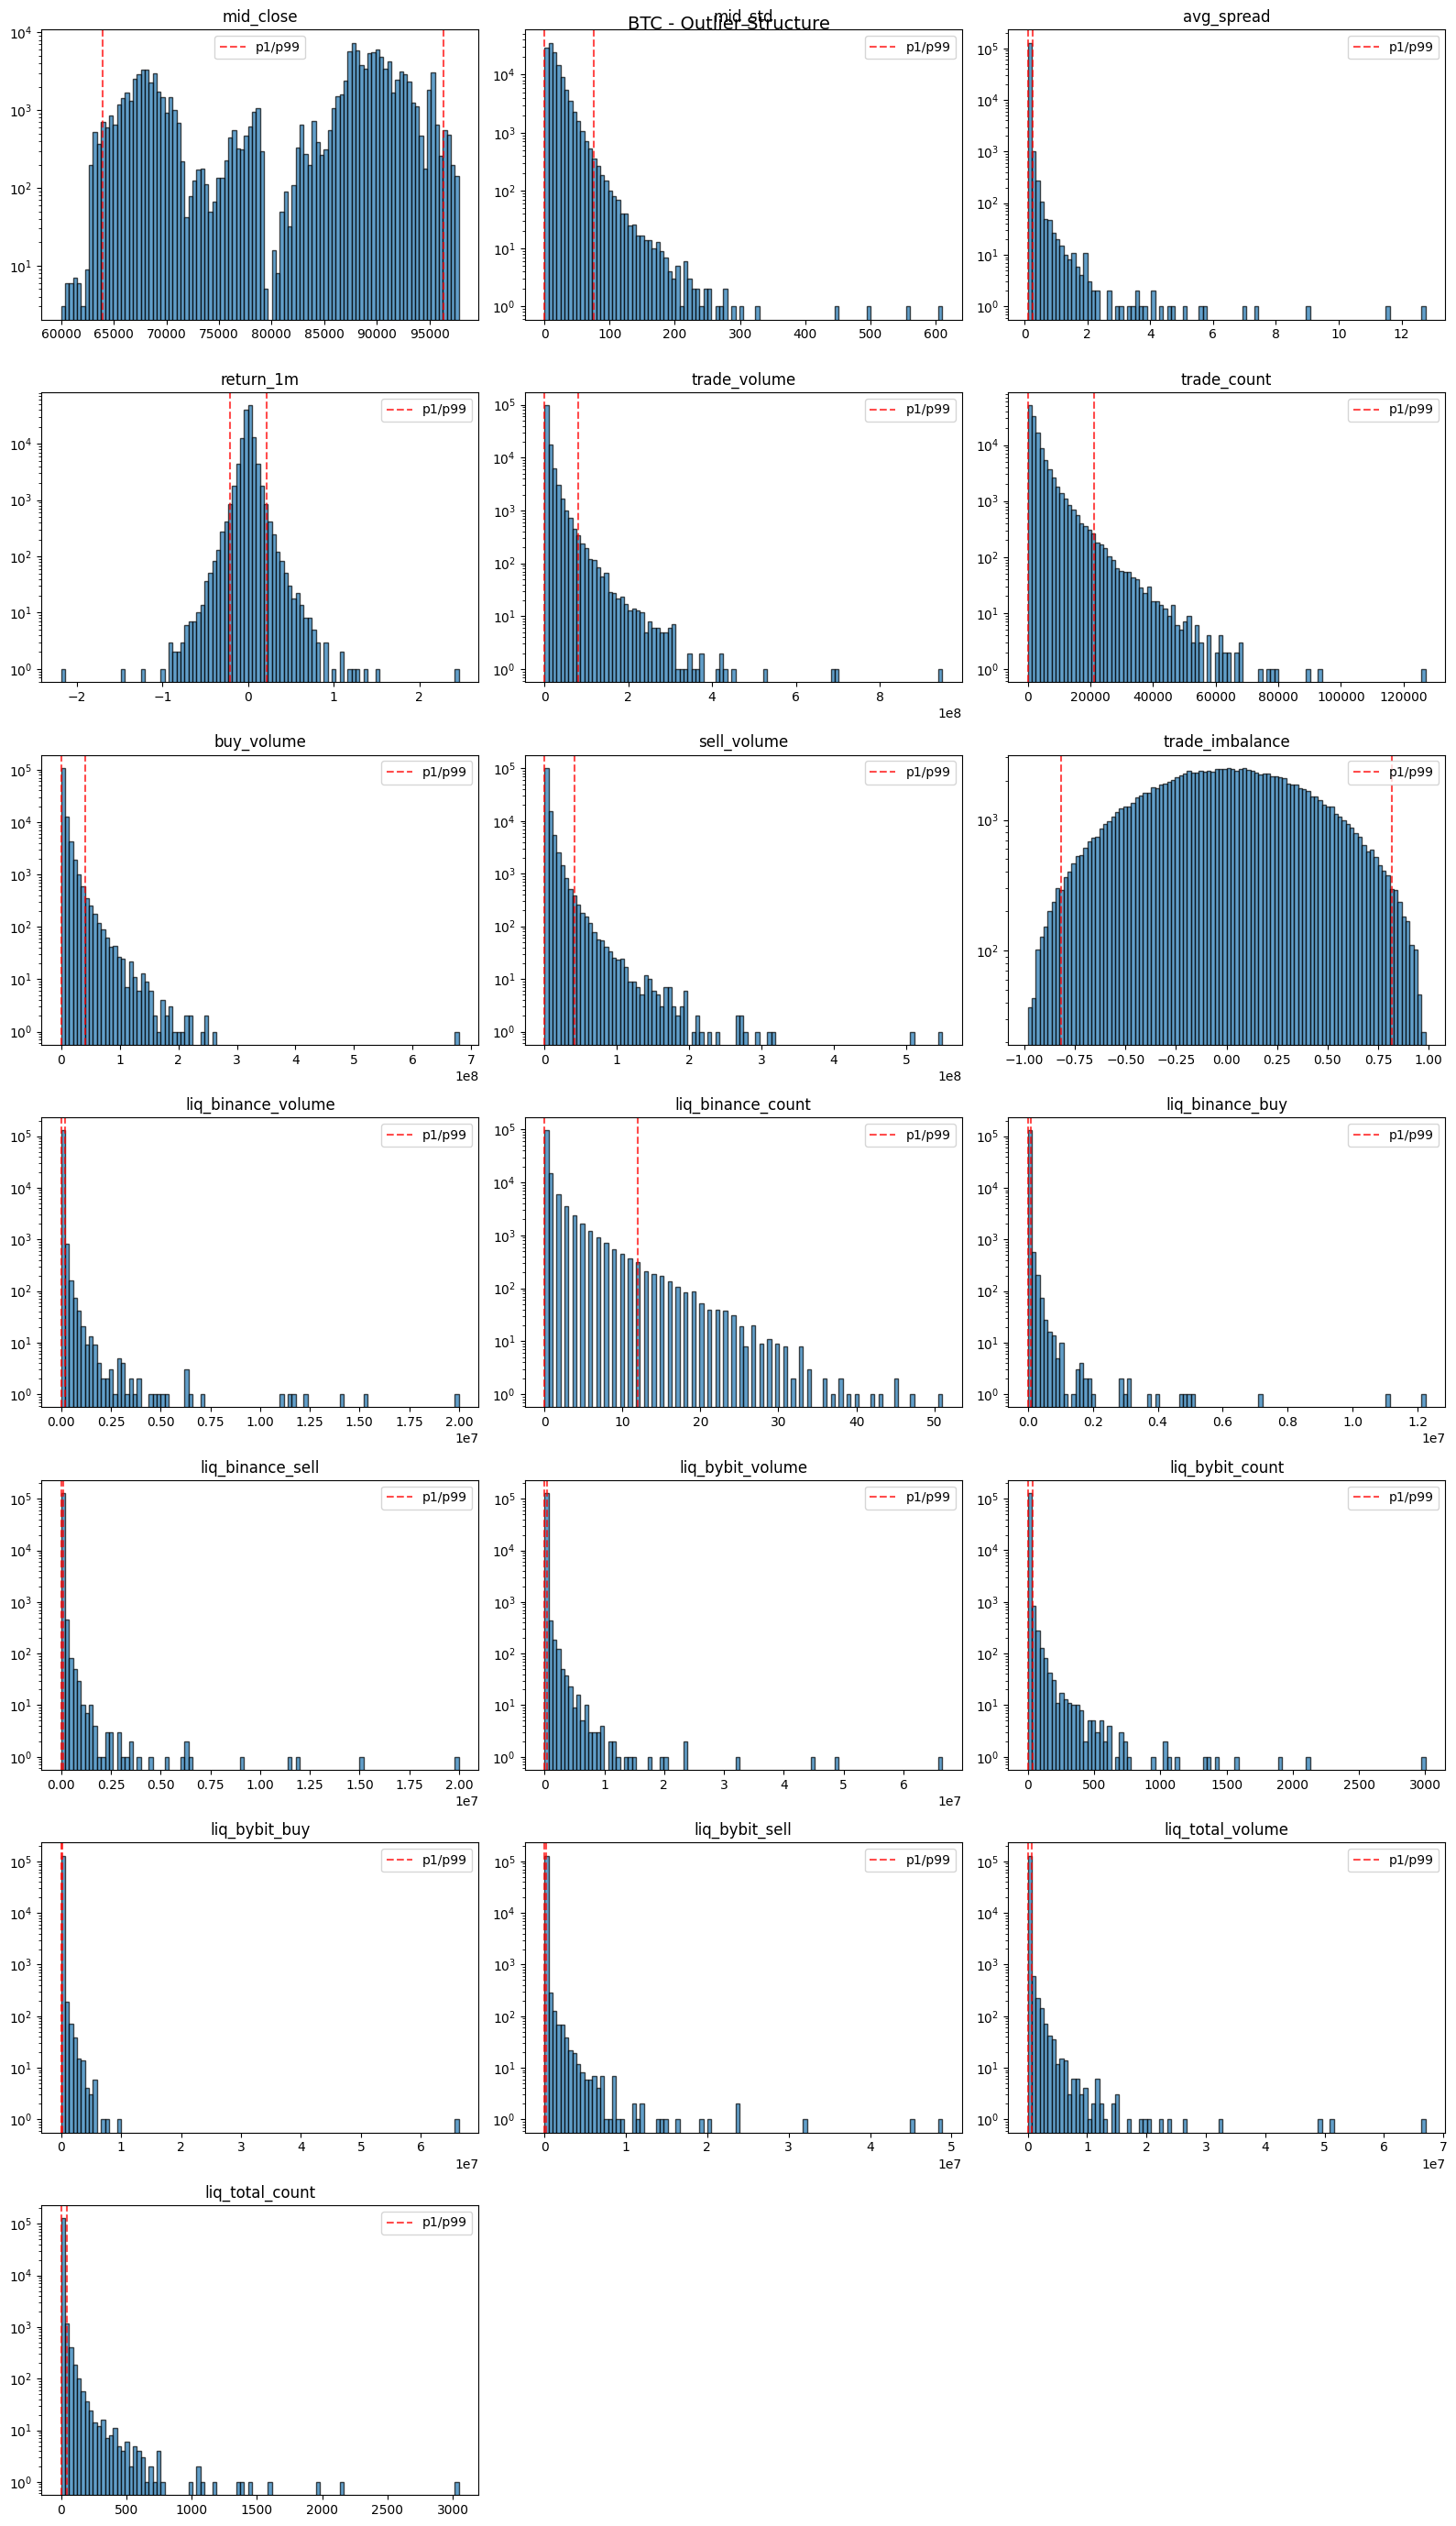

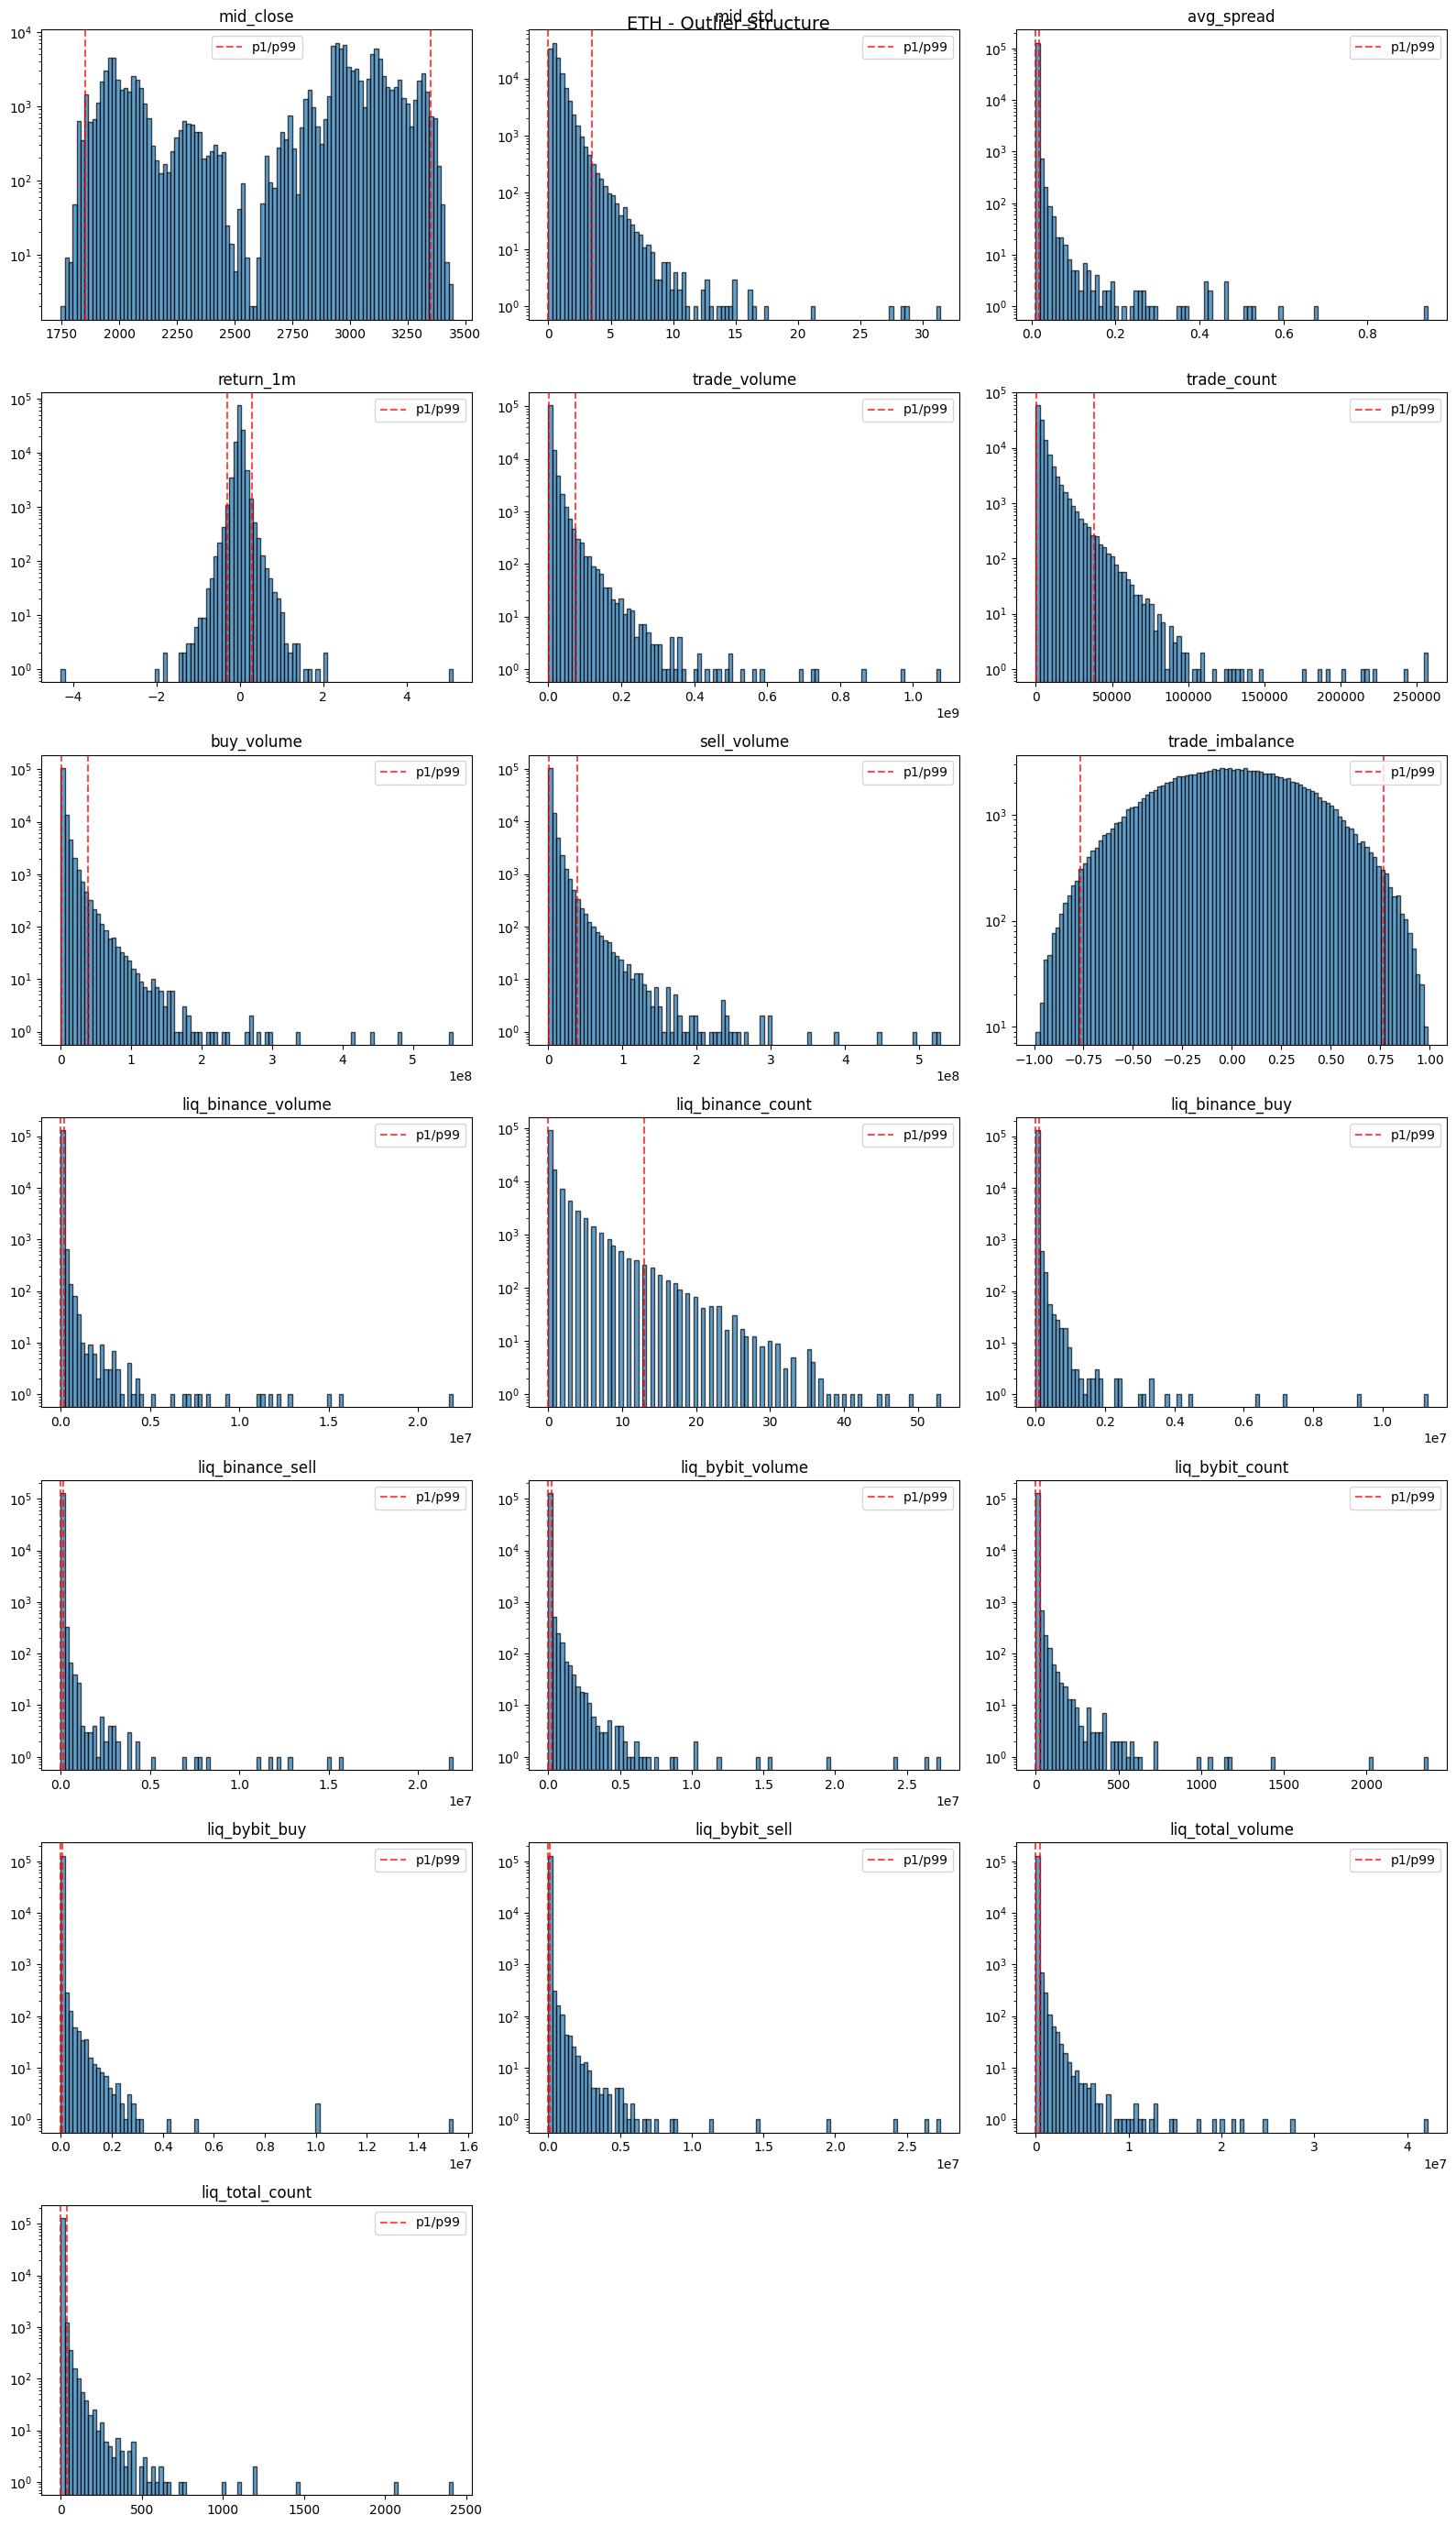

In [32]:
plot_outlier_structure(df_btc, features_full, "BTC")
plot_outlier_structure(df_eth, features_full, "ETH")

### **Outlier Structure Results.**
- Heavy tails everywhere.
- Implication: raw values will break linear models. Apply log-transform, or online EMA z-score.

### <b>1.5 Non-linearities.</b>

In [36]:
def plot_non_linearities(
    df: pl.DataFrame,
    feature_cols: list[str],
    target_col: str,
    name: str,
    n_bins: int = 20
):
    """
    Plots binned means: for each feature, splits values into n_bins quantile bins and computes mean of target in each bin.
    Shows whether relationship between feature and target is linear or not.
    """
    
    n_cols = 3
    n_rows = (len(feature_cols) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(feature_cols):
        # create quantile bins.
        temp = (
            df
            .select(pl.col(col), pl.col(target_col))
            .drop_nulls()
            .with_columns(
                (pl.col(col).rank() * n_bins / pl.col(col).rank().max())
                .floor()
                .clip(0, n_bins - 1)
                .cast(pl.Int32)
                .alias("bin")
            )
        )
        
        # mean target per bin.
        binned = (
            temp
            .group_by("bin")
            .agg(
                pl.col(col).mean().alias("feature_mean"),
                pl.col(target_col).mean().alias("target_mean"),
                pl.col(target_col).std().alias("target_std"),
                pl.len().alias("count"),
            )
            .sort("feature_mean")
        )
        
        x = binned["feature_mean"].to_numpy()
        y = binned["target_mean"].to_numpy()
        yerr = binned["target_std"].to_numpy() / np.sqrt(binned["count"].to_numpy())
        
        axes[i].errorbar(x, y, yerr=yerr, fmt="o-", capsize=3, markersize=4)
        axes[i].axhline(y=0, color="r", linestyle="--", alpha=0.5)
        axes[i].set_title(f"{col} -> {target_col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel(f"Mean {target_col}")
    
    for i in range(len(feature_cols), len(axes)):
        axes[i].set_visible(False)
    
    fig.suptitle(f"{name} - Non-linearities (binned means)", fontsize=14)
    plt.tight_layout()
    plt.show()

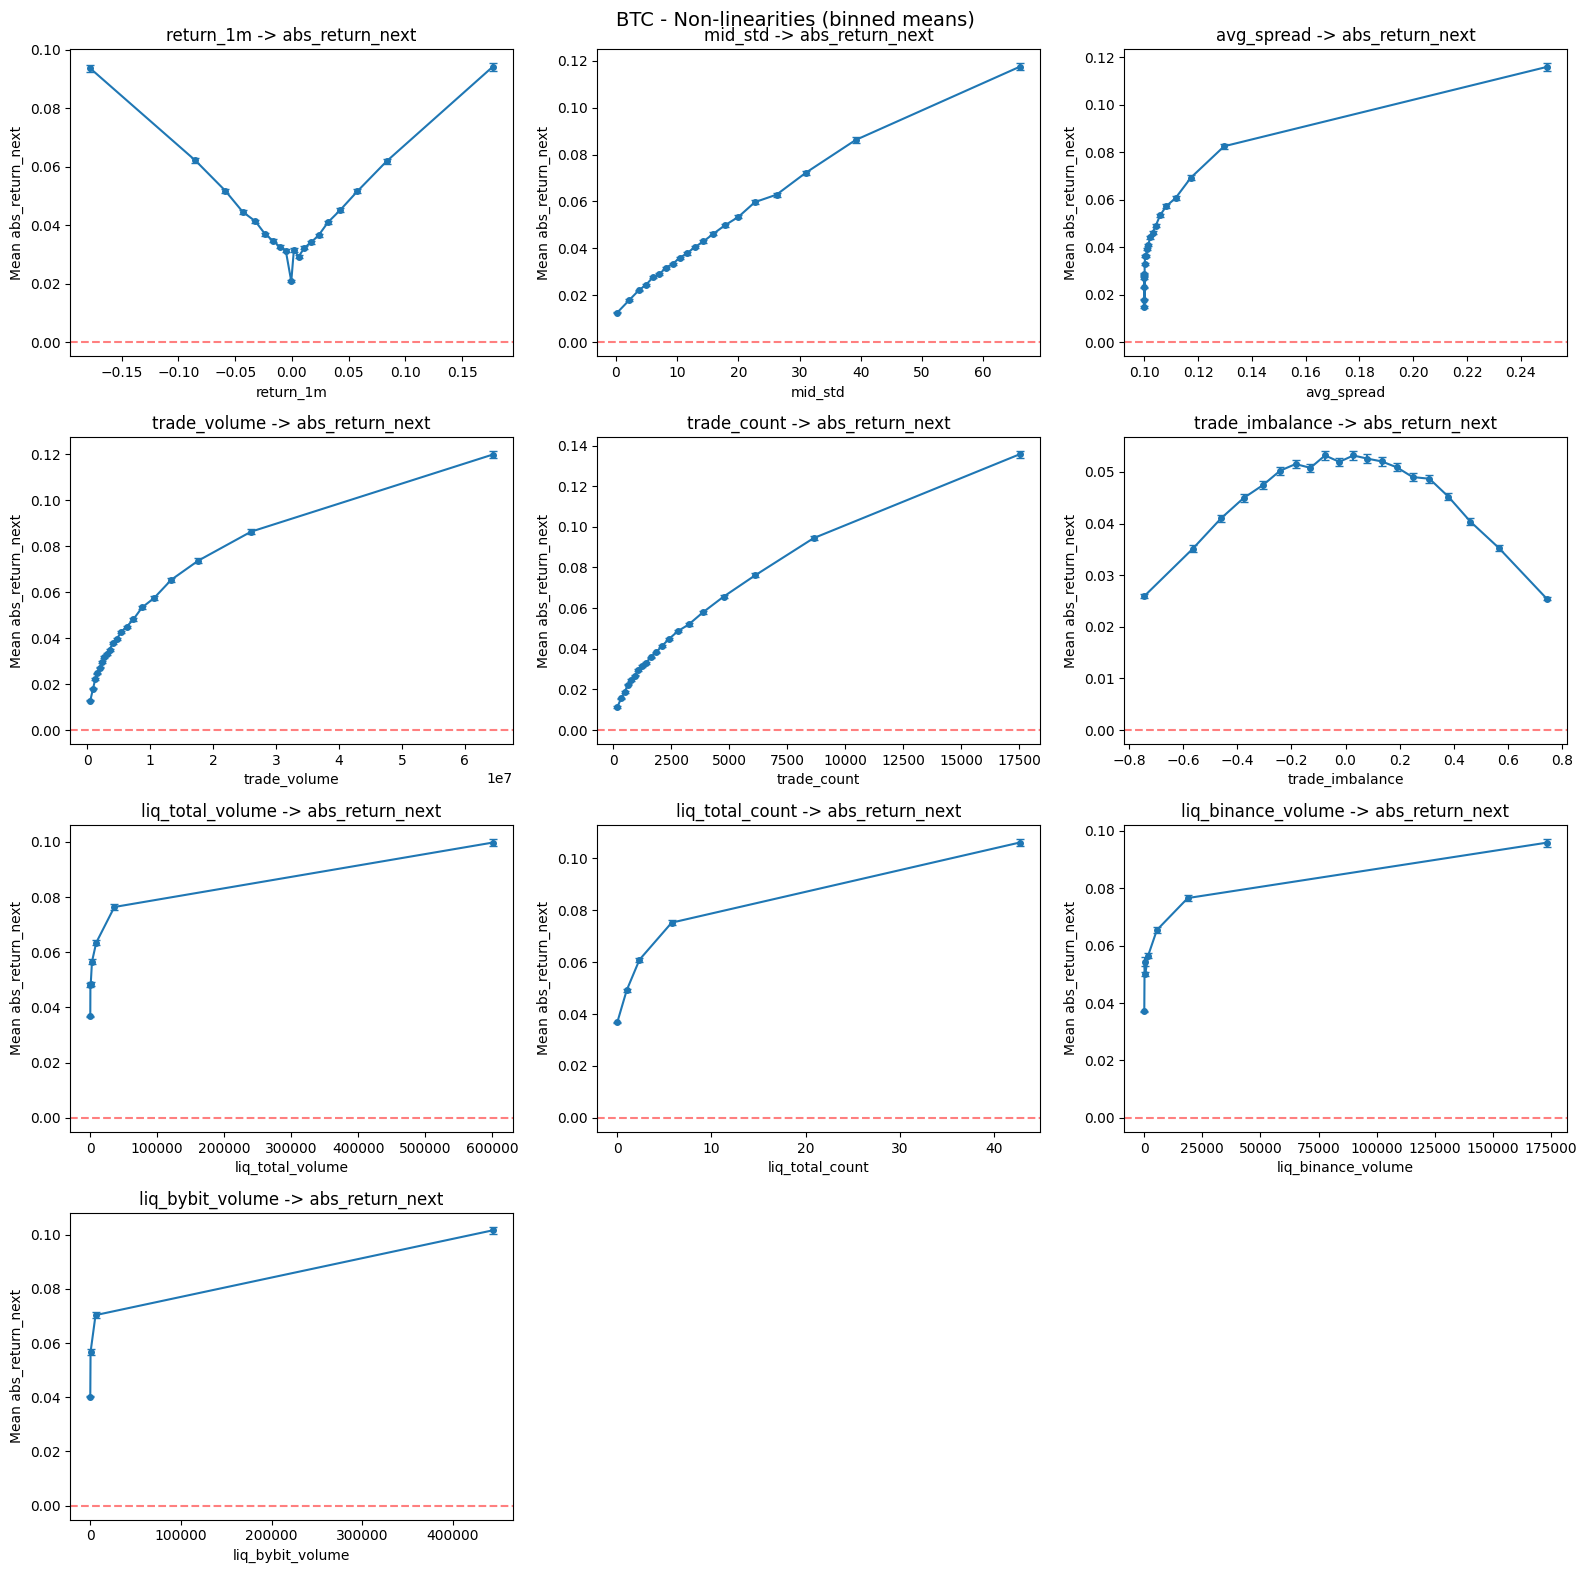

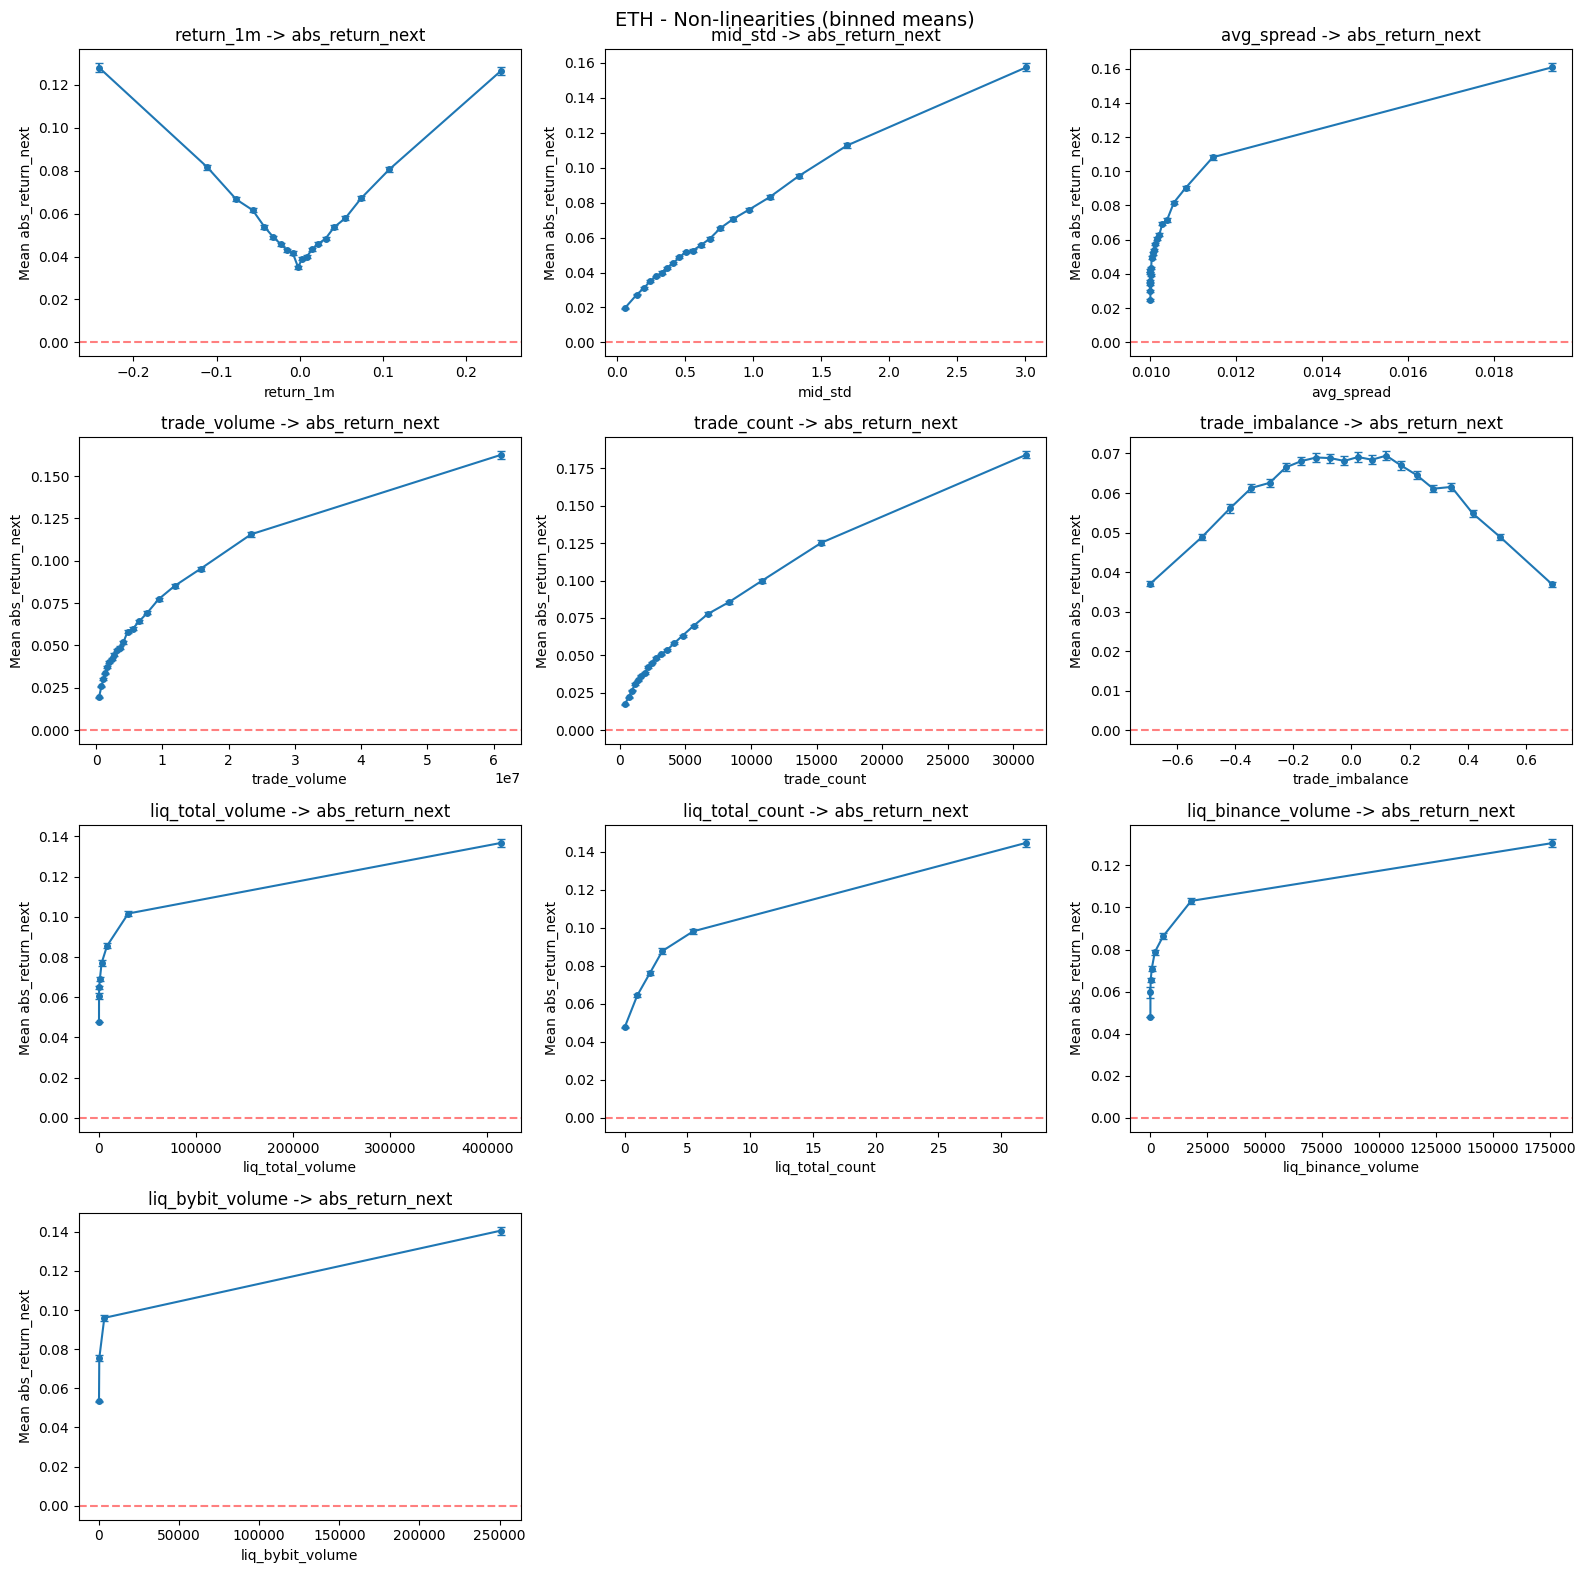

In [37]:
# non-linearities: how each feature relates to abs(return) in next minute
df_btc_nl = df_btc.with_columns(
    pl.col("return_1m").shift(-1).abs().alias("abs_return_next")
)
df_eth_nl = df_eth.with_columns(
    pl.col("return_1m").shift(-1).abs().alias("abs_return_next")
)

# show result.
plot_non_linearities(
    df_btc_nl,
    feature_cols    = features_shrink,
    target_col      = "abs_return_next",
    name            = "BTC"
)
plot_non_linearities(
    df_eth_nl,
    feature_cols    = features_shrink,
    target_col      = "abs_return_next",
    name            = "ETH"
)

### **Non-linearities Results.**
- Large minute returns (in either direction) predict increased volatility in the next minute(V-shaped relationship).
- Volatility (mid_std) and trading volume (trade_volume) also predict future volatility, but with diminishing returns: an increase in the feature from 0 to the mean yields a noticeable effect, while further increases yield less and less.
- Trade imbalance (trade_imbalance) behaves unexpectedly: maximum future volatility is observed with moderate imbalance, while volatility is lower at extreme values. Apparently, extreme imbalance occurs during quiet periods with few participants.
- The total liquidation volume (liq_total_volume) is monotonically related to future volatility: the more liquidations, the higher the volatility. This directly confirms the main hypothesis of the problem.

All identified relationships are nonlinear, which favors decision tree-based models (LightGBM, XGBoost) over linear approaches.

### <b>1.6 Regime Structure.</b>

In [49]:
def plot_regime_structure(
    df: pl.DataFrame,
    feature_cols: list[str],
    name: str,
    regime_col: str = "liq_total_volume",
):
    """
    Simple threshold-based regime detection.
    Splits data into 3 regimes by quantiles of a single feature.
    """
    
    df_clean = df.select(["datetime", "mid_close"] + feature_cols).drop_nulls()
    
    # define regimes by quantiles
    q50 = df_clean[regime_col].quantile(0.50)
    q95 = df_clean[regime_col].quantile(0.95)
    
    df_regime = df_clean.with_columns(
        pl.when(pl.col(regime_col) <= q50).then(pl.lit(0))   # calm
        .when(pl.col(regime_col) <= q95).then(pl.lit(1))     # stress
        .otherwise(pl.lit(2))                                # crisis
        .alias("regime")
    )
    
    regime_names = {0: "Calm (<=p50)", 1: "Stress (p50-p95)", 2: "Crisis (>p95)"}
    
    # Plot: feature distributions per regime.
    plot_cols = feature_cols[:6]
    fig_dist, axes_dist = plt.subplots(2, 3, figsize=(16, 10))
    axes_dist = axes_dist.flatten()
    
    for i, col in enumerate(plot_cols):
        for regime in range(3):
            vals = df_regime.filter(pl.col("regime") == regime)[col].to_numpy()
            axes_dist[i].hist(vals, bins=50, alpha=0.5, density=True, label=regime_names[regime])
        axes_dist[i].set_title(col)
        axes_dist[i].set_yscale("log")
        axes_dist[i].legend()
    
    for i in range(len(plot_cols), len(axes_dist)):
        axes_dist[i].set_visible(False)
    
    fig_dist.suptitle(f"{name} - Feature Distributions by Regime", fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Stats per regime.
    regime_stats = (
        df_regime
        .group_by("regime")
        .agg(
            pl.len().alias("count"),
            *[pl.col(c).mean().alias(f"{c}_mean") for c in feature_cols],
        )
        .sort("regime")
    )
    display(regime_stats)

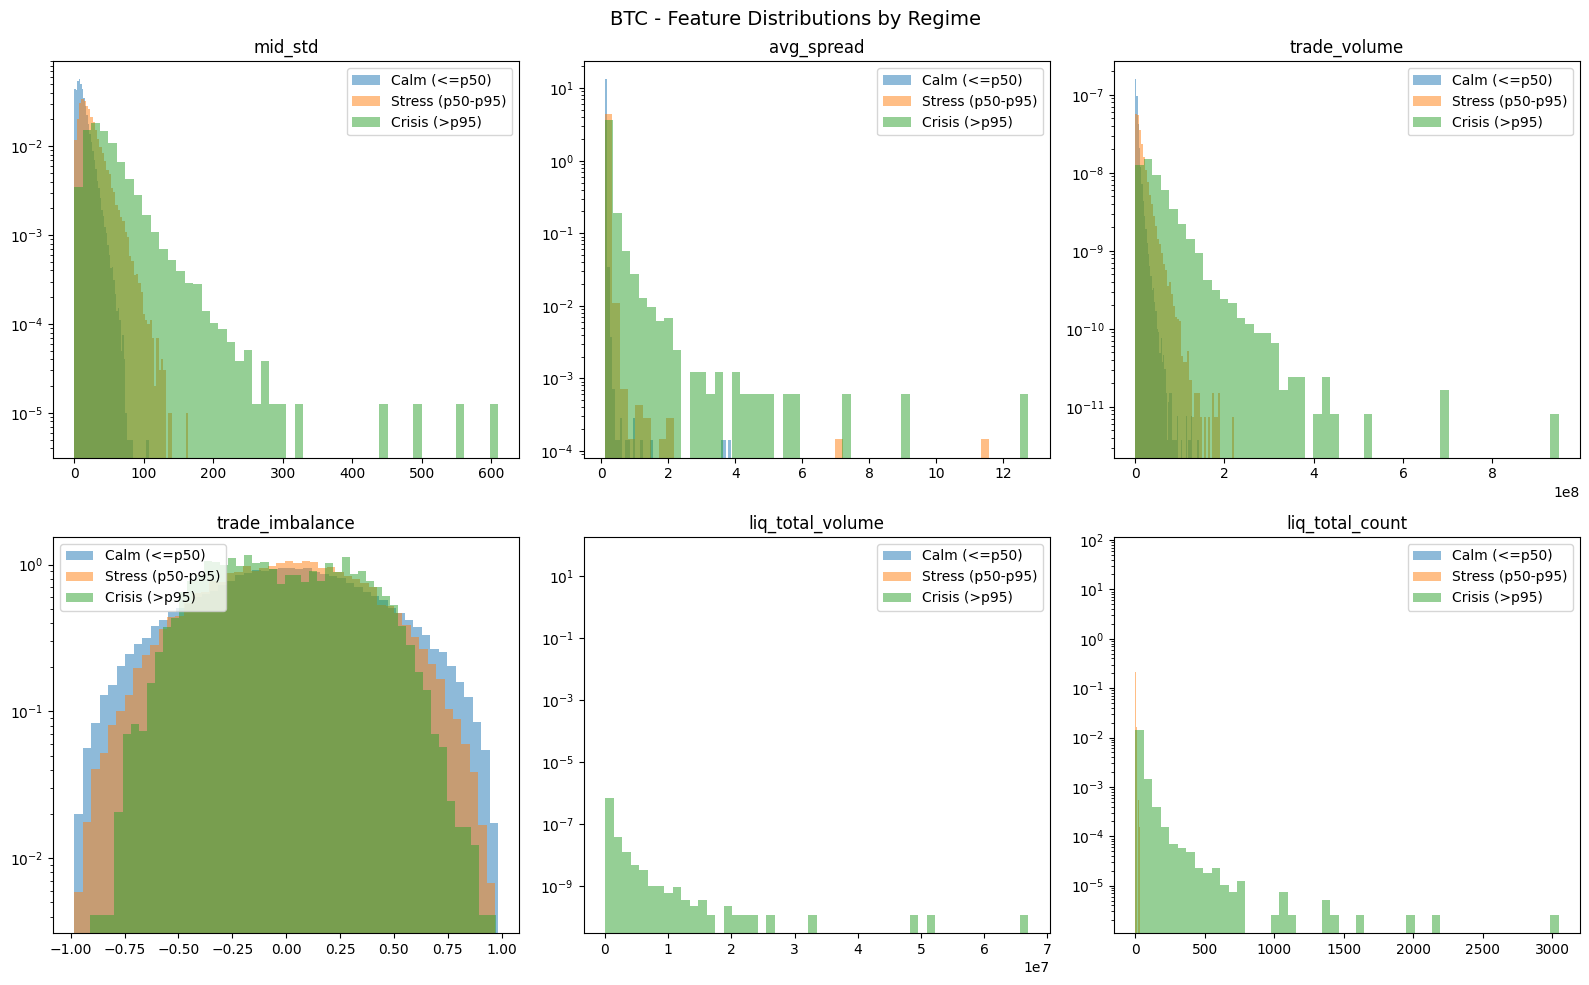

regime,count,mid_std_mean,avg_spread_mean,trade_volume_mean,trade_imbalance_mean,liq_total_volume_mean,liq_total_count_mean
i32,u32,f64,f64,f64,f64,f64,f64
0,92788,12.165108,0.104086,5.0426e6,0.002073,0.0,0.0
1,30326,23.059236,0.115375,1.3518e7,0.004072,10296.033397,2.933489
2,6480,47.476954,0.204903,5.0368e7,-0.012331,600772.955086,39.189506


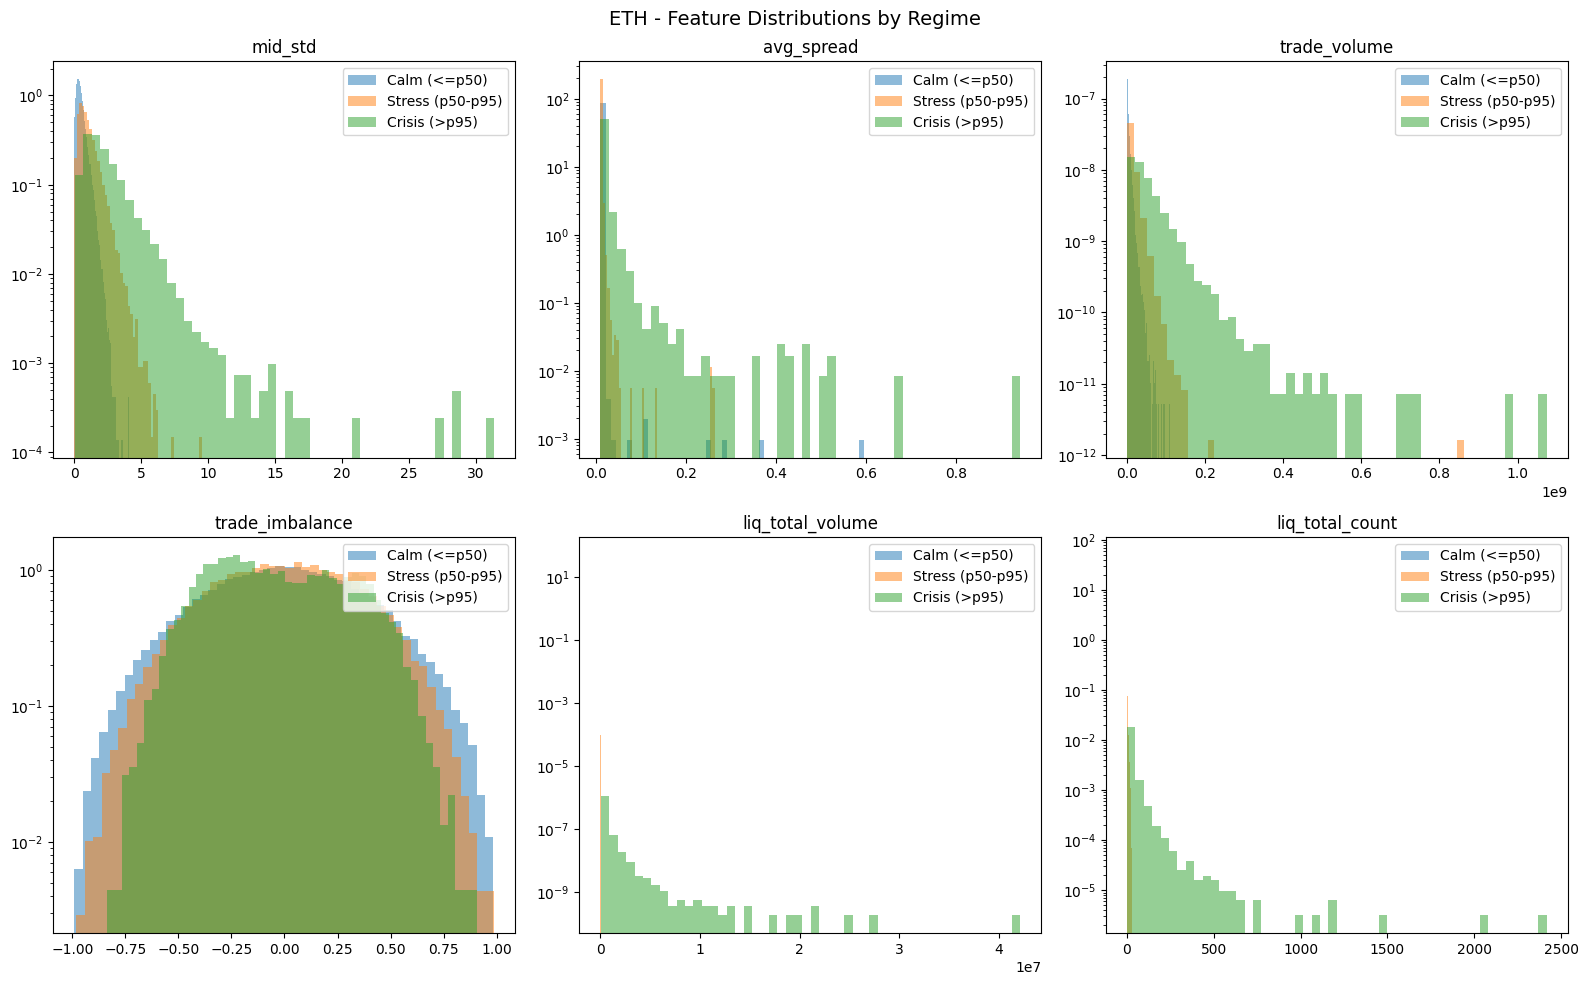

regime,count,mid_std_mean,avg_spread_mean,trade_volume_mean,trade_imbalance_mean,liq_total_volume_mean,liq_total_count_mean
i32,u32,f64,f64,f64,f64,f64,f64
0,88029,0.508616,0.010182,4.1732e6,-0.000906,0.0,0.0
1,35083,0.991619,0.010722,1.1864e7,0.003612,7803.637668,2.866146
2,6479,2.270166,0.017116,4.8476e7,-0.023296,413924.395056,29.545763


In [50]:
regime_features = [
    "mid_std", "avg_spread", "trade_volume",
    "trade_imbalance", "liq_total_volume", "liq_total_count",
]

plot_regime_structure(df_btc, regime_features, "BTC", regime_col="liq_total_volume")
plot_regime_structure(df_eth, regime_features, "ETH", regime_col="liq_total_volume")

### **Results of the market regime analysis.**

We divided all one-minute observations into three regimes based on liquidation volume (liq_total_volume): calm (below the median), stressed (from the median to the 95th percentile), and crisis (top 5%).

The regimes are clearly distinguished by their characteristics:
- In the calm regime, volatility is low, the spread remains minimal, and there are virtually no liquidations.
- In the crisis regime, volatility increases significantly, the spread widens by an order of magnitude, and trading volume explodes - the market becomes completely different.
- The only indicator that reacts weakly to the regime is trade_imbalance. The directional bias of the flow does not depend on whether liquidations are occurring or not.

A simple threshold classification based on the volume of liquidations proved sufficient for identifying meaningful regimes. In the future, one could try using methods such as HMM (Hidden Markov Model).

### <b>1.7 Correlation Matrix.</b>

In [51]:
def plot_correlation_matrix(
    df: pl.DataFrame,
    columns: list[str],
    name: str
):
    """
    Plots Pearson and Spearman correlation heatmaps between features.
    """
    
    df_clean = df.select(columns).drop_nulls().to_pandas()
    
    corr_pearson = df_clean.corr(method="pearson")
    corr_spearman = df_clean.corr(method="spearman")
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    
    # Pearson.
    im1 = axes[0].imshow(corr_pearson.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    axes[0].set_xticks(range(len(columns)))
    axes[0].set_yticks(range(len(columns)))
    axes[0].set_xticklabels(columns, rotation=45, ha="right", fontsize=8)
    axes[0].set_yticklabels(columns, fontsize=8)
    axes[0].set_title(f"{name} - Pearson")
    
    for i in range(len(columns)):
        for j in range(len(columns)):
            val = corr_pearson.values[i, j]
            axes[0].text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(val) > 0.5 else "black")
    
    fig.colorbar(im1, ax=axes[0], shrink=0.8)
    
    # Spearman.
    im2 = axes[1].imshow(corr_spearman.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    axes[1].set_xticks(range(len(columns)))
    axes[1].set_yticks(range(len(columns)))
    axes[1].set_xticklabels(columns, rotation=45, ha="right", fontsize=8)
    axes[1].set_yticklabels(columns, fontsize=8)
    axes[1].set_title(f"{name} - Spearman")
    
    for i in range(len(columns)):
        for j in range(len(columns)):
            val = corr_spearman.values[i, j]
            axes[1].text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(val) > 0.5 else "black")
    
    fig.colorbar(im2, ax=axes[1], shrink=0.8)
    
    plt.tight_layout()
    plt.show()

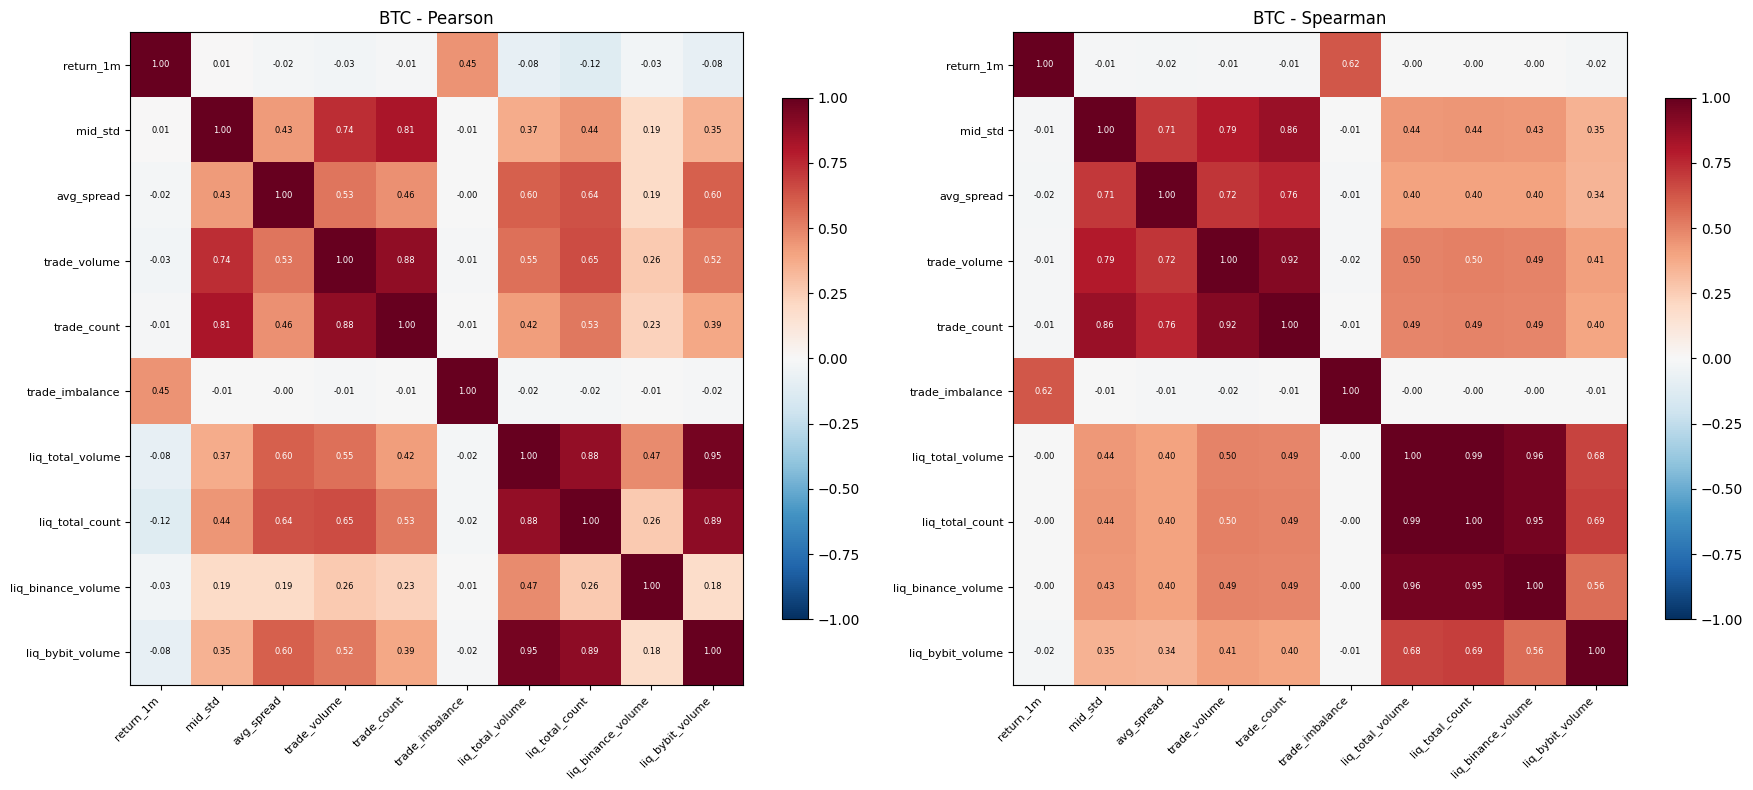

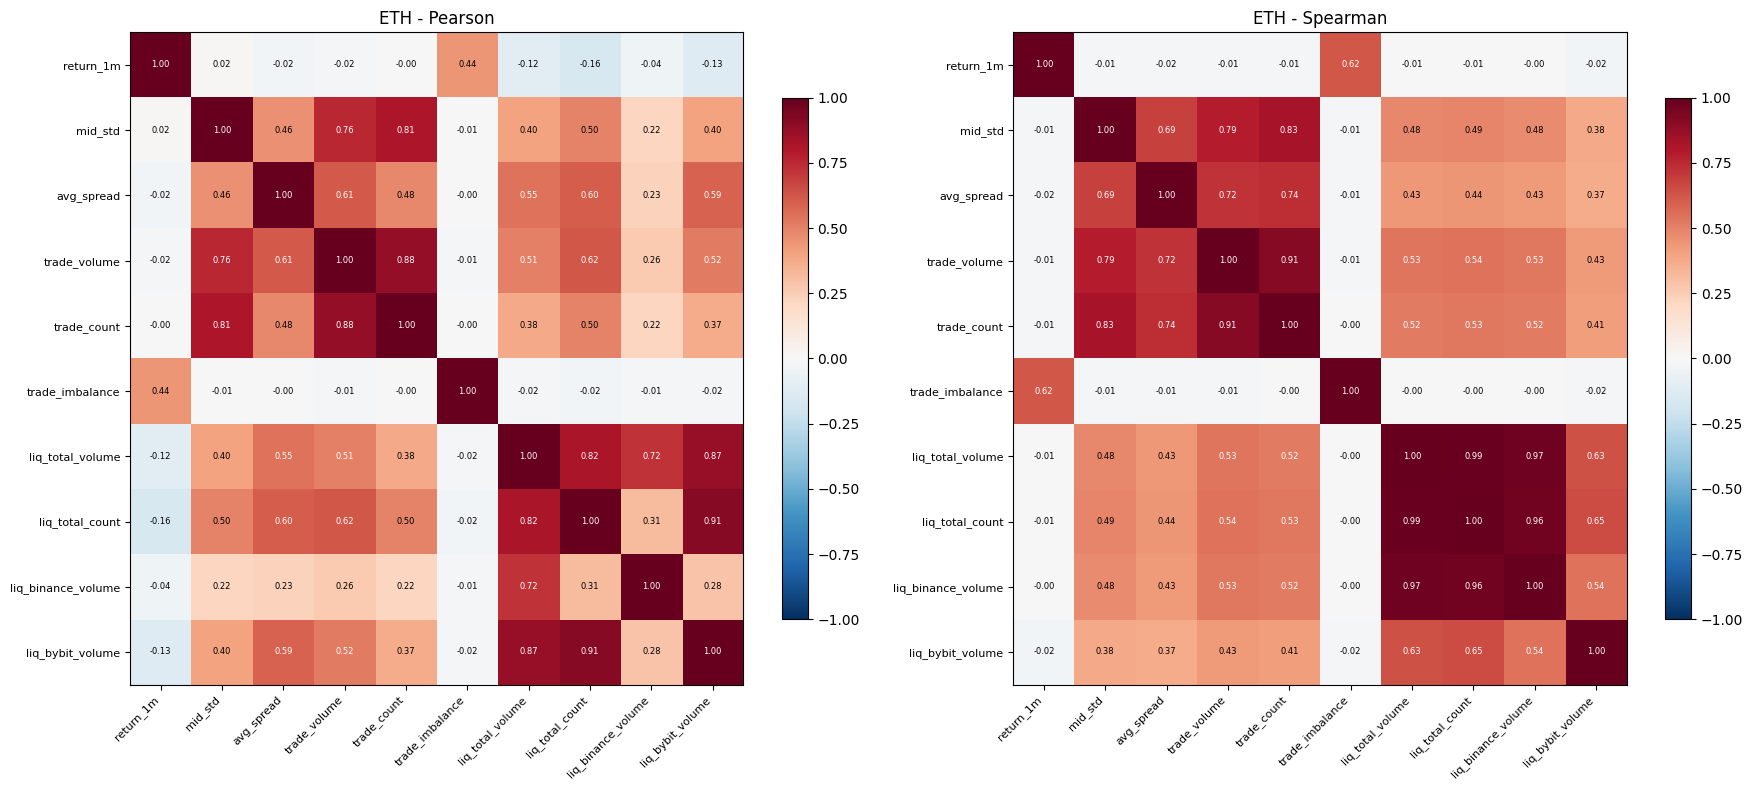

In [52]:
# show result.
plot_correlation_matrix(df_btc, features_shrink, "BTC")
plot_correlation_matrix(df_eth, features_shrink, "ETH")

### **Correlation Matrix Results.**
- Volatility block (mid_std, spread, trade_volume, trade_count) - intercorrelated 0.7–0.9. We can use 1–2 features.
- Liquidation block - intercorrelated 0.88–0.95, but only 0.4–0.6 with the volatility block. Liquidations contain unique information.
- `liq_binance` vs `liq_bybit` - Spearman 0.56. Both are useful and not fully redundant.
- Optimal feature set: one of (mid_std or trade_volume) + liq_total_volume + trade_imbalance.